In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
# Read dataset
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')

print(df.head())
print(df.shape)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
df = df.dropna()
df = df.drop_duplicates()
# Select features
X = df[['SALES', 'QUANTITYORDERED', 'PRICEEACH']]

# Feature scaling
scaler = StandardScaler()
X = scaler.fit_transform(X)

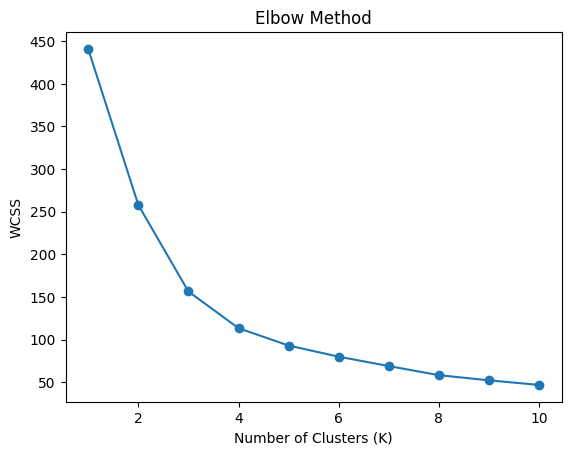

In [4]:
# Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

# Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()



In [5]:
# Apply K-Means
k = 3  # Select K based on the elbow graph

model = KMeans(n_clusters=k, random_state=42, n_init=10)
df['Cluster'] = model.fit_predict(X)



      SALES  QUANTITYORDERED  PRICEEACH  Cluster
10  3965.66               37     100.00        2
21  1451.00               20      72.55        0
40  4905.39               21     100.00        2
47  3944.70               30     100.00        2
51  2416.56               24     100.00        2


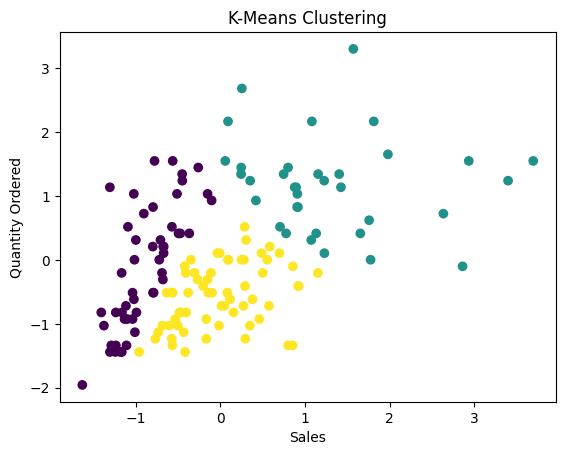

In [6]:
# Display clusters
print(df[['SALES', 'QUANTITYORDERED', 'PRICEEACH', 'Cluster']].head())

# Visualize clusters
plt.scatter(X[:, 0], X[:, 1], c=df['Cluster'])
plt.xlabel('Sales')
plt.ylabel('Quantity Ordered')
plt.title('K-Means Clustering')
plt.show()
